Что предсказываем:
    - Целевая переменная: 'Пtм в печи финиш, сред.'

Тип задачи:
    - Регрессия (обучение с учителем)

Метрика качества:
    - R² - для понимания, насколько модель объясняет данные

Критерии успеха:
    - R² > 45%

По метрикам попробовать сделать SHAP или permutation_importance и выделить 15-20 наиболее значимых значений и попробовать прогнать модель через них

## ML Model

## Обработка данных

In [1]:
import pandas as pd
# import numpy as np

data = pd.read_csv('DataClear12.csv')

data_new = data.copy()

target_Y = data_new.columns[-1] 

x = data_new.drop(columns=[target_Y])
y = data_new[target_Y]

#обработка выбросов
# q1 = y.quantile(0.25)
# q2 = y.quantile(0.75)
# iqr = q2 - q1
# lower_bound = q1 - 1.5*iqr
# upper_bound = q2 - 1.5*iqr

# outliers_mask = (y < lower_bound) | (y > upper_bound)
# print(f"Количество выбросов в целевой переменной: {outliers_mask.sum()}")

# keep_mask = ~outliers_mask
# x = x[keep_mask]
# y = y[keep_mask]

# print(f"Размер данных после удаления выбросов: {x.shape[0]} строк")

#удаляем дубликаты строк
temp_df = pd.concat([x, y], axis=1)
temp_df = temp_df.drop_duplicates(keep='first')

x = temp_df.iloc[:, :-1]
y = temp_df.iloc[:, -1]
print(f"Размер после удаления дубликатов: {x.shape[0]} строк")

print(f"Итоговое количество признаков: {x.shape[1]}")
print(f"Итоговое количество строк: {x.shape[0]}")

Размер после удаления дубликатов: 56631 строк
Итоговое количество признаков: 17
Итоговое количество строк: 56631


## Разделение выборки

In [2]:
from sklearn.model_selection import train_test_split

x_temp, X_test, y_temp, y_test = train_test_split(
    x, y, test_size=0.3, random_state=42
    ) 

# Затем делим оставшуюся часть на train и validation
x_train, X_val, y_train, y_val = train_test_split(
    x_temp, y_temp, test_size=0.25, random_state=42
)

print(f"Размер train: {x_train.shape[0]} строк")
print(f"Размер validation: {X_val.shape[0]} строк")
print(f"Размер test: {X_test.shape[0]} строк")

# Сохраняем названия столбцов для дальнейшего использования
feature_names = x_train.columns.tolist()

Размер train: 29730 строк
Размер validation: 9911 строк
Размер test: 16990 строк



## Базовая модель с масштабированием


In [16]:
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

#Масштабирование
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(x_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

X_train_scaled_df = pd.DataFrame(X_train_scaled, columns=feature_names)
X_val_scaled_df = pd.DataFrame(X_val_scaled, columns=feature_names)
X_train_scaled_df
X_val_scaled_df

# Обучение Ridge Regression (линейная модель с L2-регуляризацией)
model_ridge = Ridge(alpha=1.0, random_state=42)
model_ridge.fit(X_train_scaled, y_train)

# Предсказания
y_train_pred_ridge = model_ridge.predict(X_train_scaled)
y_val_pred_ridge = model_ridge.predict(X_val_scaled)
y_test_pred_ridge = model_ridge.predict(X_test_scaled)

# Расчет метрик для Ridge 
def print_metrics(y_true, y_pred, dataset_name):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    print(f"\n{dataset_name}:")
    print(f"MAE: {mae:.3f} °C")
    print(f"RMSE: {rmse:.3f} °C")
    print(f"R²: {r2:.3f}")
    return {'mae': mae, 'rmse': rmse, 'r2': r2}

print("\n--- Ridge Regression ---")
ridge_metrics_train = print_metrics(y_train, y_train_pred_ridge, "Train")
ridge_metrics_val = print_metrics(y_val, y_val_pred_ridge, "Validation")
ridge_metrics_test = print_metrics(y_test, y_test_pred_ridge, "Test")

# Сохраняем baseline метрики
baseline_mae = ridge_metrics_val['mae']
print(f"\nBASELINE MAE (Validation): {baseline_mae:.3f} °C")


--- Ridge Regression ---

Train:
MAE: 5.096 °C
RMSE: 8.078 °C
R²: 0.033

Validation:
MAE: 5.110 °C
RMSE: 7.806 °C
R²: 0.027

Test:
MAE: 5.221 °C
RMSE: 8.522 °C
R²: 0.025

BASELINE MAE (Validation): 5.110 °C


## Анализ коэффицентов

In [4]:
coef_df = pd.DataFrame({
    'feature': x.columns,
    'coefficient': model_ridge.coef_, # Вес (насколько сильно меняется Y при изменении X)
    'abs_importance': np.abs(model_ridge.coef_)
}).sort_values('abs_importance', ascending=False)

print("Топ-24 признаков по коэффициентам:")
print(coef_df.head(24))
print("\nПризнаки с минимальным влиянием (коэффициент < 0.1):")
print(coef_df[coef_df['abs_importance'] < 0.1])

Топ-24 признаков по коэффициентам:
                                              feature  coefficient  \
13               Толщина полимерного покрытия,  эмаль     2.179744   
6   Прочность полимерного покрытия при изгибе 180°...    -2.052648   
10    Твердость полимерного покрытия, лицевая сторона     1.580484   
12               Толщина полимерного покрытия,  общая    -0.989674   
0                                               Блеск     0.820217   
11               Толщина полимерного покрытия,  грунт     0.738483   
15  Толщина полимерного покрытия, обратная сторона...     0.466469   
8   Сопротивление растрескиванию при испытании на ...    -0.460312   
3                        Отклонение по цвету дельта L    -0.347891   
7                          Разнооттеночность дельта Е     0.297976   
4                        Отклонение по цвету дельта b    -0.296238   
2                    Массовая доля нелетучих веществ.    -0.188316   
14  Толщина полимерного покрытия, лицевая сторона,...  

## Permutation Importance


Самые важные 24 признака по Permutation Importance:
                                              feature  importance_mean  \
13               Толщина полимерного покрытия,  эмаль         0.147426   
6   Прочность полимерного покрытия при изгибе 180°...         0.122916   
10    Твердость полимерного покрытия, лицевая сторона         0.083517   
12               Толщина полимерного покрытия,  общая         0.030320   
0                                               Блеск         0.022454   
11               Толщина полимерного покрытия,  грунт         0.019430   
15  Толщина полимерного покрытия, обратная сторона...         0.008334   
8   Сопротивление растрескиванию при испытании на ...         0.003353   
7                          Разнооттеночность дельта Е         0.003237   
3                        Отклонение по цвету дельта L         0.002569   
4                        Отклонение по цвету дельта b         0.001279   
5       Отклонение по цвету дельта b, лицевая сторона      

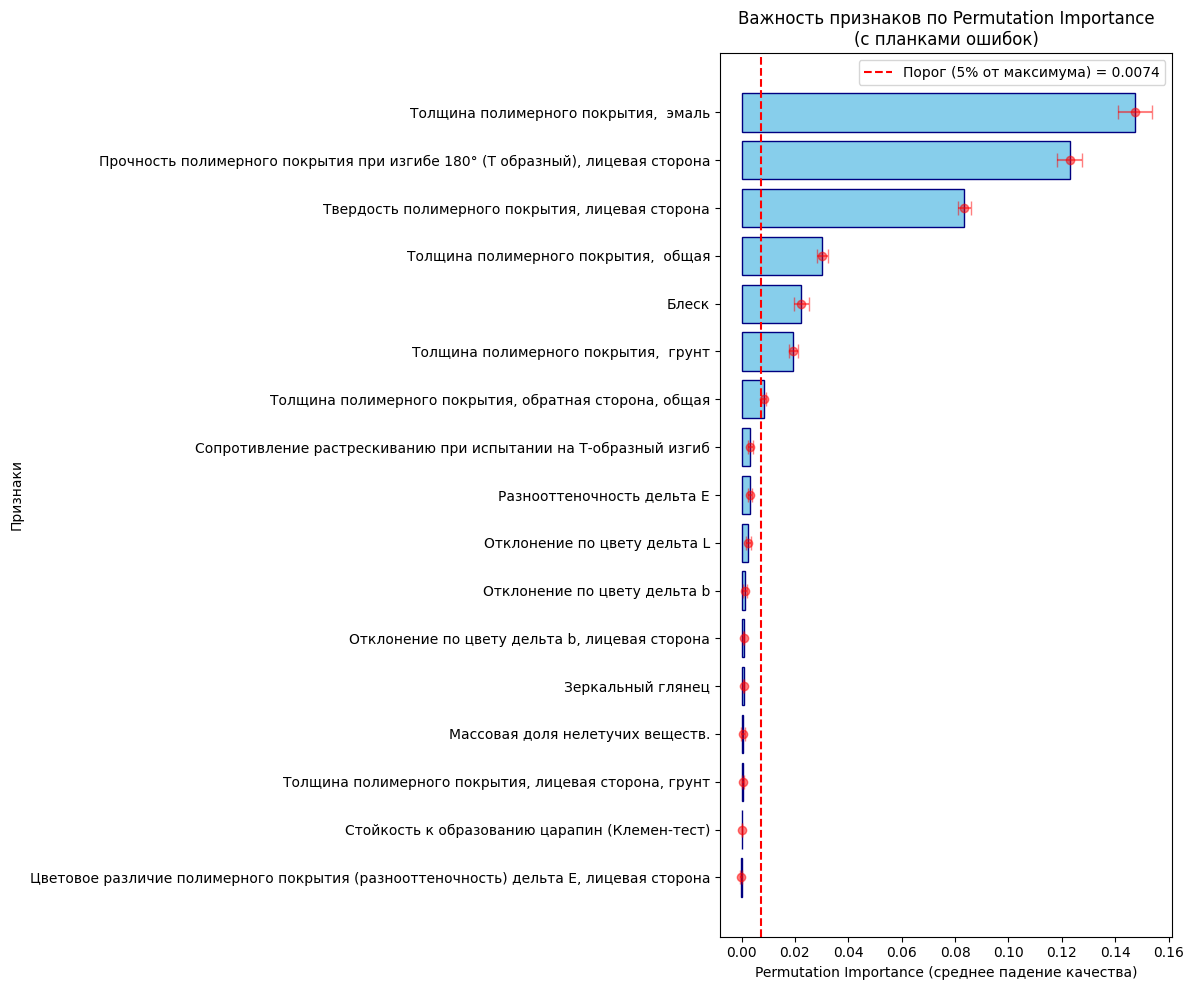

In [5]:
from sklearn.inspection import permutation_importance
import matplotlib.pyplot as plt
# import seaborn as sns

# Считаем важность с 3 повторами
result = permutation_importance(
    model_ridge, 
    X_val_scaled, 
    y_val,
    n_repeats = 5,
    random_state = 42,
    n_jobs = -1
)

perm_df = pd.DataFrame({
    'feature': x.columns,
    'importance_mean': result.importances_mean, # Важные признаки (их изменения сильно влияют на Y)
    'importance_std': result.importances_std # Разброс важности при перемешиваниях
}).sort_values('importance_mean', ascending = False)

print("\nСамые важные 24 признака по Permutation Importance:")
print(perm_df.head(24))

threshold_perm = perm_df['importance_mean'].max() * 0.05 # Важность < 5% от максимума
weak_perm = perm_df[perm_df['importance_mean'] < threshold_perm]['feature'].tolist()
print(f"\nПризнаки для удаления по Permutation: {weak_perm}")
print(f"\nПризнаки для удаления по Permutation: {weak_perm}")

# Берем топ-24 признака
top_perm = perm_df.head(24)

plt.figure(figsize=(12, 10))
bars = plt.barh(top_perm['feature'], top_perm['importance_mean'], 
                color='skyblue', edgecolor='navy')

# Добавляем планки ошибок (стандартное отклонение)
plt.errorbar(top_perm['importance_mean'], 
             range(len(top_perm)), 
             xerr = top_perm['importance_std'], 
             fmt = 'o', color = 'red', capsize = 5, alpha = 0.5)

# Добавляем красную линию порога (5% от максимума)
threshold = top_perm['importance_mean'].max() * 0.05
plt.axvline(x = threshold, color = 'red', linestyle = '--', 
            label = f'Порог (5% от максимума) = {threshold:.4f}')

plt.xlabel('Permutation Importance (среднее падение качества)')
plt.ylabel('Признаки')
plt.title('Важность признаков по Permutation Importance\n(с планками ошибок)')
plt.gca().invert_yaxis() # Чтобы самый важный был сверху
plt.legend()
plt.tight_layout()
plt.show()

## SHAP

Background dataset has 29730 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=29730 when initializing the masker.



Топ-24 по SHAP:
                                              feature  shap_mean
6   Прочность полимерного покрытия при изгибе 180°...   1.815181
10    Твердость полимерного покрытия, лицевая сторона   1.371902
13               Толщина полимерного покрытия,  эмаль   1.304216
12               Толщина полимерного покрытия,  общая   0.596373
0                                               Блеск   0.499603
15  Толщина полимерного покрытия, обратная сторона...   0.389619
11               Толщина полимерного покрытия,  грунт   0.371247
8   Сопротивление растрескиванию при испытании на ...   0.362038
3                        Отклонение по цвету дельта L   0.277297
4                        Отклонение по цвету дельта b   0.232320
7                          Разнооттеночность дельта Е   0.229674
14  Толщина полимерного покрытия, лицевая сторона,...   0.162714
2                    Массовая доля нелетучих веществ.   0.142402
16  Цветовое различие полимерного покрытия (разноо...   0.093306
5       

C:\Users\Nick\AppData\Roaming\Python\Python314\site-packages\shap\plots\_beeswarm.py:1150: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


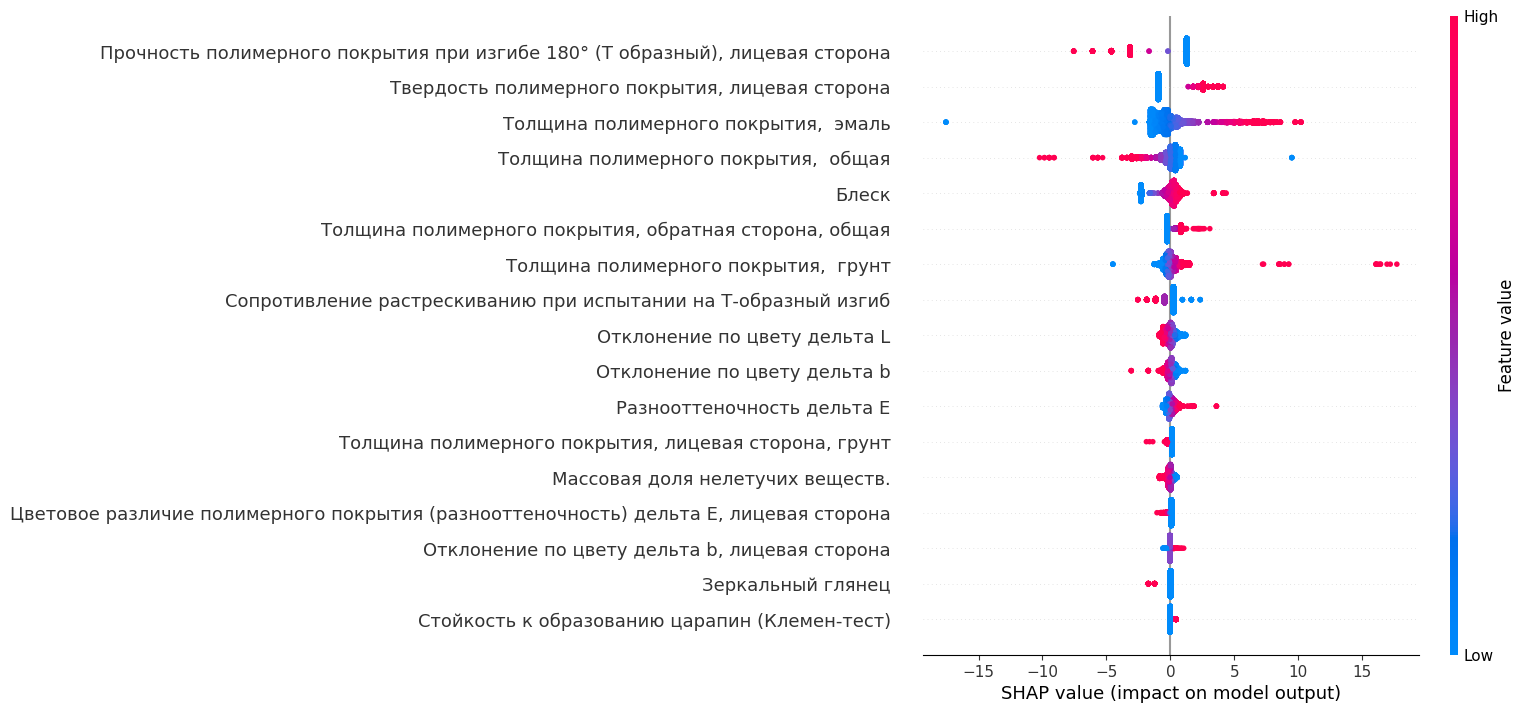


Признаки для удаления по SHAP: ['Отклонение по цвету дельта b, лицевая сторона', 'Зеркальный глянец', 'Стойкость к образованию царапин (Клемен-тест)']


In [6]:
import shap

explainer = shap.LinearExplainer(model_ridge, X_train_scaled) # Метод LinearExplainer для линейной регрессии
shap_values = explainer.shap_values(X_val_scaled)

shap_importance = pd.DataFrame({
    'feature': x.columns,
    'shap_mean': np.abs(shap_values).mean(axis = 0) # Средний абсолютный SHAP
}).sort_values('shap_mean', ascending = False)

print("\nТоп-24 по SHAP:")
print(shap_importance.head(24))

shap.summary_plot(shap_values, X_val_scaled, feature_names = x.columns)

threshold_shap = shap_importance['shap_mean'].max() * 0.05 # SHAP <5%
weak_shap = shap_importance[shap_importance['shap_mean'] < threshold_shap]['feature'].tolist()
print(f"\nПризнаки для удаления по SHAP: {weak_shap}")

## Результат


╔══════════════════════════════════════════════════════════════════╗
║                    ИТОГОВЫЙ ОТЧЕТ ПО BASELINE                    ║
╠══════════════════════════════════════════════════════════════════╣
║  Модель:              Ridge Regression (L2-регуляризация)        ║
║  Тип задачи:          Регрессия                                  ║
║  Целевая переменная:  Пtм в печи финиш, сред.                    ║
╠══════════════════════════════════════════════════════════════════╣
║  Количество признаков: 17                                        ║
║  Количество строк: 56631                                         ║
╠══════════════════════════════════════════════════════════════════╣
║  МЕТРИКИ НА VALIDATION:                                          ║
║    MAE: 5.110 °C                                                 ║
║    RMSE: 7.806 °C                                                ║
║    R²: 0.027                                                     ║
╠════════════════════════════════

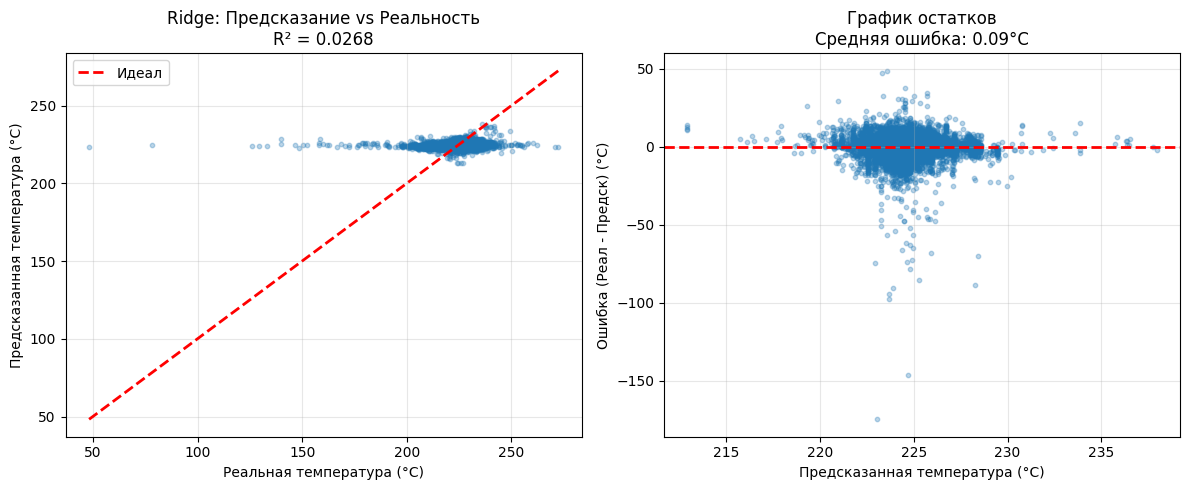

In [8]:
import matplotlib.pyplot as plt
from sklearn.metrics import r2_score
from sklearn.metrics import r2_score

print(f"""
╔══════════════════════════════════════════════════════════════════╗
║                    ИТОГОВЫЙ ОТЧЕТ ПО BASELINE                    ║
╠══════════════════════════════════════════════════════════════════╣
║  Модель:              Ridge Regression (L2-регуляризация)        ║
║  Тип задачи:          Регрессия                                  ║
║  Целевая переменная:  Пtм в печи финиш, сред.                    ║
╠══════════════════════════════════════════════════════════════════╣
║  Количество признаков: {x.shape[1]}                                        ║
║  Количество строк: {x.shape[0]}                                         ║
╠══════════════════════════════════════════════════════════════════╣
║  МЕТРИКИ НА VALIDATION:                                          ║
║    MAE: {ridge_metrics_val['mae']:.3f} °C                                                 ║
║    RMSE: {ridge_metrics_val['rmse']:.3f} °C                                                ║
║    R²: {ridge_metrics_val['r2']:.3f}                                                     ║
╠══════════════════════════════════════════════════════════════════╣
║  МЕТРИКИ НА TEST:                                                ║
║    MAE: {ridge_metrics_test['mae']:.3f} °C                                                 ║
║    RMSE: {ridge_metrics_test['rmse']:.3f} °C                                                ║
║    R²: {ridge_metrics_test['r2']:.3f}                                                     ║
╚══════════════════════════════════════════════════════════════════╝
""")
y_pred_ridge = model_ridge.predict(X_val_scaled)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.scatter(y_val, y_pred_ridge, alpha=0.3, s=10)
plt.plot([y_val.min(), y_val.max()], [y_val.min(), y_val.max()], 'r--', lw=2, label='Идеал')
plt.xlabel('Реальная температура (°C)')
plt.ylabel('Предсказанная температура (°C)')
plt.title(f'Ridge: Предсказание vs Реальность\nR² = {r2_score(y_val, y_pred_ridge):.4f}')
plt.legend()
plt.grid(True, alpha=0.3)
plt.subplot(1, 2, 2)
residuals = y_val - y_pred_ridge
plt.scatter(y_pred_ridge, residuals, alpha=0.3, s=10)
plt.axhline(y=0, color='r', linestyle='--', lw=2)
plt.xlabel('Предсказанная температура (°C)')
plt.ylabel('Ошибка (Реал - Предск) (°C)')
plt.title(f'График остатков\nСредняя ошибка: {residuals.mean():.2f}°C')
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


## XGBoost

Сравнительная таблица метрик
Метрика      Ridge Train     Ridge Val       Ridge Test      XGB Train       XGB Val         XGB Test       
MAE         5.096          5.110          5.221          3.864          4.288          4.414          
RMSE        8.078          7.806          8.522          6.418          6.991          7.788          
R²          0.0331         0.0268         0.0249         0.3896         0.2194         0.1856         

 УЛУЧШЕНИЕ НА VALIDATION:
 R²:  0.0268 -> 0.2194  (+19.26 процентных пунктов)
 MAE: 5.110°C -> 4.288°C  (-16.1%)


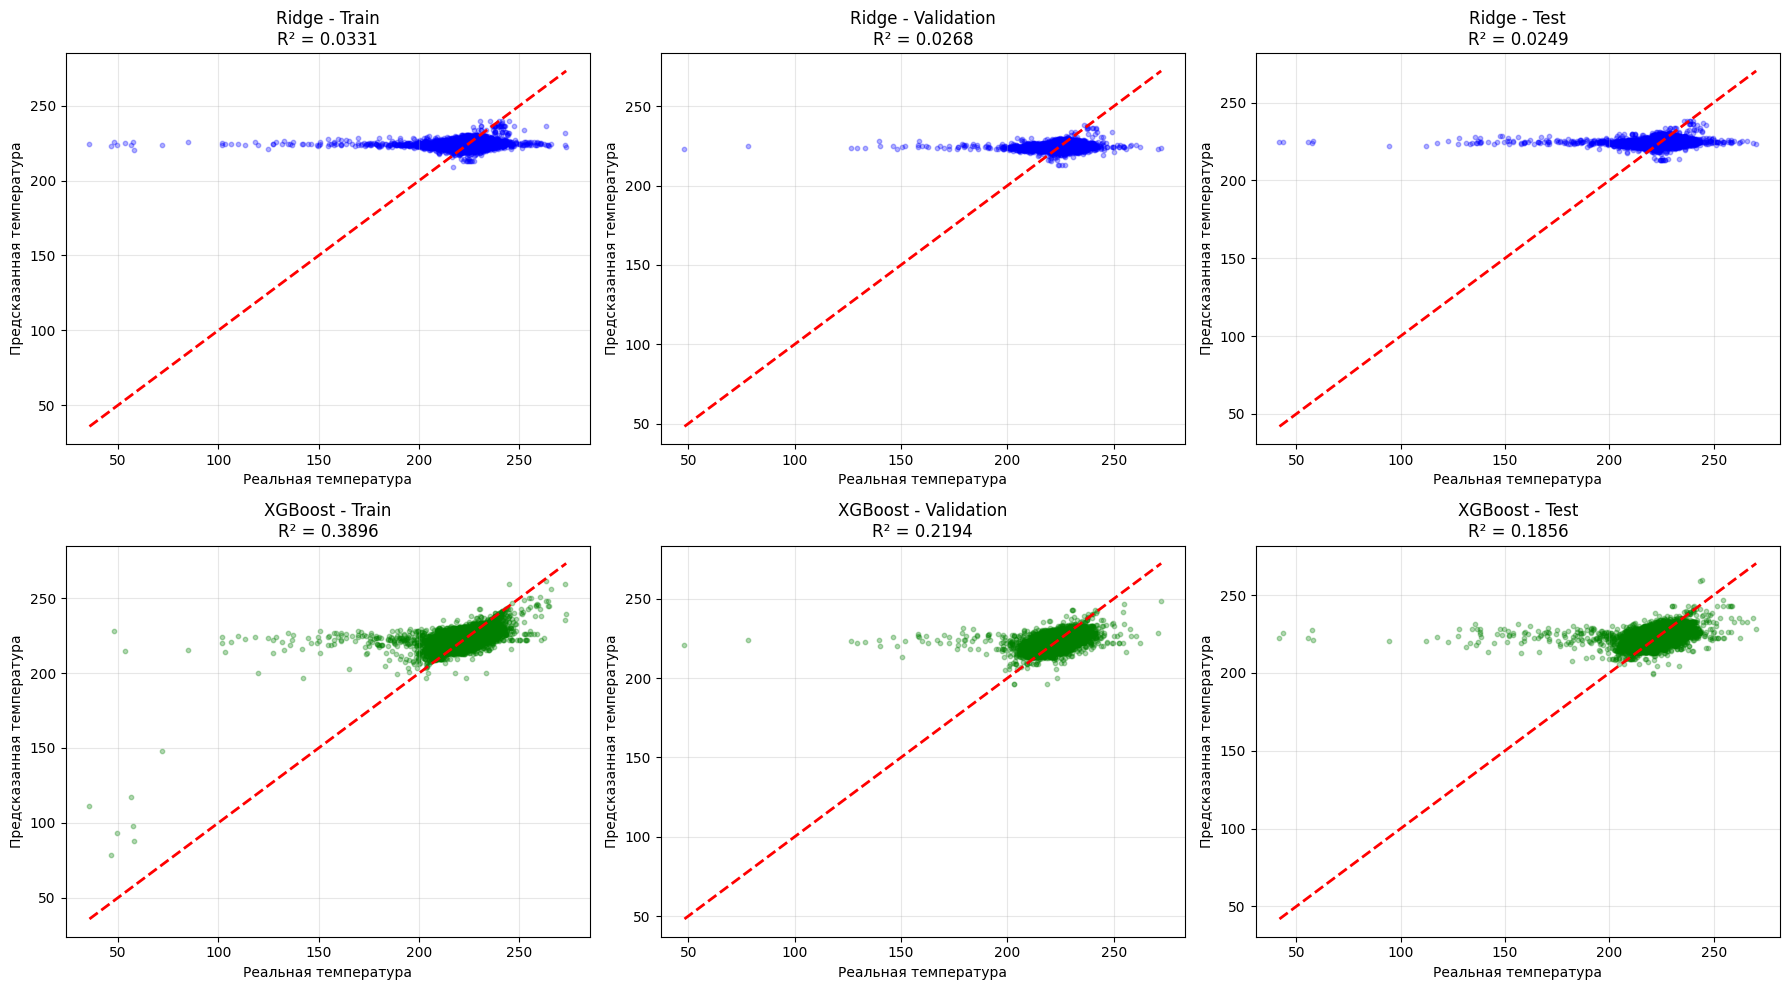

Топ-10 признаков по XGBOOST
                                                       feature  importance
                          Толщина полимерного покрытия,  эмаль    0.120707
Сопротивление растрескиванию при испытании на Т-образный изгиб    0.103753
                                    Разнооттеночность дельта Е    0.089073
                                  Отклонение по цвету дельта b    0.078234
                          Толщина полимерного покрытия,  грунт    0.078161
                          Толщина полимерного покрытия,  общая    0.070387
                                  Отклонение по цвету дельта L    0.069276
                              Массовая доля нелетучих веществ.    0.067299
                                                         Блеск    0.057549
         Толщина полимерного покрытия, обратная сторона, общая    0.049036


In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from xgboost import XGBRegressor

# Создаем модель XGBoost
xgb_model = XGBRegressor( # Только лучшие значения через подбор
    n_estimators = 200, # Количество деревьев
    learning_rate = 0.05, # Скорость обучения (шаг)
    max_depth=  8, # Глубина дерева
    subsample = 0.8, # Доля объектов для каждого дерева
    colsample_bytree = 0.9, # Доля признаков для каждого дерева
    random_state = 42,
    n_jobs = -1 # Используем все ядра CPU
)

# Обучаем на train
xgb_model.fit(x_train, y_train)

# Предсказания на всех выборках
y_train_pred_xgb = xgb_model.predict(x_train)
y_val_pred_xgb = xgb_model.predict(X_val)
y_test_pred_xgb = xgb_model.predict(X_test)

def calc_metrics(y_true, y_pred, name):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    return {'MAE': mae, 'RMSE': rmse, 'R²': r2}

metrics_xgb = {
    'Train': calc_metrics(y_train, y_train_pred_xgb, 'Train'),
    'Validation': calc_metrics(y_val, y_val_pred_xgb, 'Validation'),
    'Test': calc_metrics(y_test, y_test_pred_xgb, 'Test')
}

y_train_pred_ridge = model_ridge.predict(X_train_scaled)
y_val_pred_ridge = model_ridge.predict(X_val_scaled)
y_test_pred_ridge = model_ridge.predict(X_test_scaled)

metrics_ridge = {
    'Train': calc_metrics(y_train, y_train_pred_ridge, 'Train'),
    'Validation': calc_metrics(y_val, y_val_pred_ridge, 'Validation'),
    'Test': calc_metrics(y_test, y_test_pred_ridge, 'Test')
}

print("Сравнительная таблица метрик")

print(f"{'Метрика':<12} {'Ridge Train':<15} {'Ridge Val':<15} {'Ridge Test':<15} {'XGB Train':<15} {'XGB Val':<15} {'XGB Test':<15}")

for metric in ['MAE', 'RMSE', 'R²']:
    row = f"{metric:<12}"
    for model, metrics in [('Ridge', metrics_ridge), ('XGB', metrics_xgb)]:
        for dataset in ['Train', 'Validation', 'Test']:
            val = metrics[dataset][metric]
            if metric == 'R²':
                row += f"{val:<15.4f}"
            else:
                row += f"{val:<15.3f}"
    print(row)

r2_ridge_val = metrics_ridge['Validation']['R²']
r2_xgb_val = metrics_xgb['Validation']['R²']
r2_improvement = (r2_xgb_val - r2_ridge_val) * 100

mae_ridge_val = metrics_ridge['Validation']['MAE']
mae_xgb_val = metrics_xgb['Validation']['MAE']
mae_improvement = (mae_ridge_val - mae_xgb_val) / mae_ridge_val * 100

print(f"\n УЛУЧШЕНИЕ НА VALIDATION:")
print(f" R²:  {r2_ridge_val:.4f} -> {r2_xgb_val:.4f}  (+{r2_improvement:.2f} процентных пунктов)")
print(f" MAE: {mae_ridge_val:.3f}°C -> {mae_xgb_val:.3f}°C  (-{mae_improvement:.1f}%)")

fig, axes = plt.subplots(2, 3, figsize = (18, 10))

datasets = [
    ('Train', y_train, y_train_pred_ridge, y_train_pred_xgb),
    ('Validation', y_val, y_val_pred_ridge, y_val_pred_xgb),
    ('Test', y_test, y_test_pred_ridge, y_test_pred_xgb)
]

for idx, (name, y_true, y_pred_ridge, y_pred_xgb) in enumerate(datasets):
    # Ridge
    ax = axes[0, idx]
    ax.scatter(y_true, y_pred_ridge, alpha = 0.3, s = 10, color = 'blue')
    ax.plot([y_true.min(), y_true.max()], [y_true.min(), y_true.max()], 'r--', lw = 2)
    ax.set_xlabel('Реальная температура')
    ax.set_ylabel('Предсказанная температура')
    ax.set_title(f'Ridge - {name}\nR² = {r2_score(y_true, y_pred_ridge):.4f}')
    ax.grid(True, alpha = 0.3)
    
    # XGBoost
    ax = axes[1, idx]
    ax.scatter(y_true, y_pred_xgb, alpha=0.3, s=10, color='green')
    ax.plot([y_true.min(), y_true.max()], [y_true.min(), y_true.max()], 'r--', lw = 2)
    ax.set_xlabel('Реальная температура')
    ax.set_ylabel('Предсказанная температура')
    ax.set_title(f'XGBoost - {name}\nR² = {r2_score(y_true, y_pred_xgb):.4f}')
    ax.grid(True, alpha = 0.3)

plt.tight_layout()
plt.show()

print("Топ-10 признаков по XGBOOST")


# Важность признаков в XGBoost
feature_importance_xgb = pd.DataFrame({
    'feature': feature_names,
    'importance': xgb_model.feature_importances_
}).sort_values('importance', ascending = False)

print(feature_importance_xgb.head(10).to_string(index = False))


## Подбор параметров для модели xgb (уже отработано, а с большем кол-вом параметро слишком долго перебирает и не хватает вычислительной мощности моего компуктера)

In [10]:
# from sklearn.model_selection import GridSearchCV

# param_grid_2 = {
#     'n_estimators': [200, 300, 500],
#     'max_depth': [8, 10, 12],
#     'learning_rate': [0.03, 0.05, 0.07],
#     'subsample': [0.8, 0.9, 1.0],
#     'colsample_bytree': [0.7, 0.8, 0.9]
# }

# grid_search_2 = GridSearchCV(XGBRegressor(random_state=42), param_grid_2, cv=3, scoring='r2', n_jobs=-1)
# grid_search_2.fit(x_train, y_train)

# print(f"Лучшие параметры (2-й проход): {grid_search_2.best_params_}")
# print(f"Лучший R² на CV: {grid_search_2.best_score_:.4f}")

## Визуализация Ожидание vs Реальность (xgb)

Размер y_val: 9911
Размер y_pred_xgb:16990

Тип y_val: <class 'pandas.Series'>
Тип y_pred_xgb: <class 'numpy.ndarray'>
Индексы y_val: [48495, 13813, 10857, 28103, 13636]


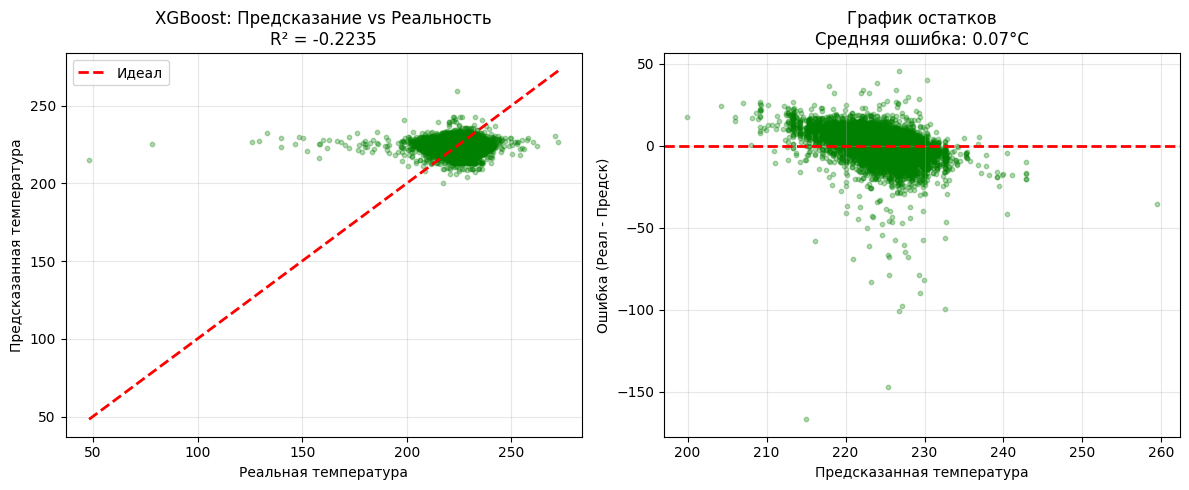

In [11]:
import matplotlib.pyplot as plt
from sklearn.metrics import r2_score
import numpy as np

print(f"Размер y_val: {len(y_val)}")
print(f"Размер y_pred_xgb:{len(y_pred_xgb)}")

print(f"\nТип y_val: {type(y_val)}")
print(f"Тип y_pred_xgb: {type(y_pred_xgb)}")

if hasattr(y_val, 'index'):
    print(f"Индексы y_val: {y_val.index[:5].tolist() if len(y_val) > 5 else y_val.index.tolist()}")
if hasattr(y_pred_xgb, 'index'):
    print(f"Индексы y_pred_xgb:    {y_pred_xgb.index[:5].tolist() if len(y_pred_xgb) > 5 else y_pred_xgb.index.tolist()}")

min_len = min(len(y_val), len(y_pred_xgb))

y_true = np.array(y_val)[:min_len]
y_pred = np.array(y_pred_xgb)[:min_len]

plt.figure(figsize = (12, 5))

plt.subplot(1, 2, 1)
plt.scatter(y_true, y_pred, alpha = 0.3, s = 10, color = 'green')
plt.plot([y_true.min(), y_true.max()], [y_true.min(), y_true.max()], 'r--', lw = 2, label = 'Идеал')
plt.xlabel('Реальная температура')
plt.ylabel('Предсказанная температура')
plt.title(f'XGBoost: Предсказание vs Реальность\nR² = {r2_score(y_true, y_pred):.4f}')
plt.legend()
plt.grid(True, alpha = 0.3)

plt.subplot(1, 2, 2)
residuals = y_true - y_pred
plt.scatter(y_pred, residuals, alpha = 0.3, s = 10, color = 'green')
plt.axhline(y = 0, color = 'r', linestyle = '--', lw = 2)
plt.xlabel('Предсказанная температура')
plt.ylabel('Ошибка (Реал - Предск)')
plt.title(f'График остатков\nСредняя ошибка: {residuals.mean():.2f}°C')
plt.grid(True, alpha = 0.3)

plt.tight_layout()
plt.show()

## Сохранение моделей

In [15]:
import os
import joblib
import pandas as pd
import numpy as np
from datetime import datetime
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

#  Класс для сохранения модели и отчётов в екселе
class ModelSaver:
    
    def __init__(self, model, model_name='model', save_dir='.'):
        self.model = model
        self.model_name = model_name
        self.save_dir = save_dir

        os.makedirs(f'{save_dir}/models', exist_ok=True)
        os.makedirs(f'{save_dir}/reports', exist_ok=True)
    
    @staticmethod
    def calc_metrics(y_true, y_pred):
        return {
            'MAE': mean_absolute_error(y_true, y_pred),
            'RMSE': np.sqrt(mean_squared_error(y_true, y_pred)),
            'R2': r2_score(y_true, y_pred)
        }
    
    # Сохранение модели
    def save_model(self):
        path = f'{self.save_dir}/models/{self.model_name}.joblib'
        joblib.dump(self.model, path)
        print(f"Модель сохранена: {path}")
        return path
    
    # Такой мини отчёт в екселе о успехе модели
    def save_excel(self, X_train, y_train, X_val, y_val, X_test, y_test, feature_names):
        
        # Предсказания
        pred_train = self.model.predict(X_train)
        pred_val = self.model.predict(X_val)
        pred_test = self.model.predict(X_test)
        
        # Метрики
        m_train = self.calc_metrics(y_train, pred_train)
        m_val = self.calc_metrics(y_val, pred_val)
        m_test = self.calc_metrics(y_test, pred_test)
        
        metrics_df = pd.DataFrame([
            ['Train', m_train['MAE'], m_train['RMSE'], m_train['R2']],
            ['Validation', m_val['MAE'], m_val['RMSE'], m_val['R2']],
            ['Test', m_test['MAE'], m_test['RMSE'], m_test['R2']]
        ], columns = ['Dataset', 'MAE', 'RMSE', 'R2'])
        
        # Важность признаков
        if hasattr(self.model, 'feature_importances_'):
            importance_df = pd.DataFrame({
                'feature': feature_names,
                'importance': self.model.feature_importances_
            }).sort_values('importance', ascending=False)
        else:
            # Для моделей без feature importances
            importance_df = pd.DataFrame({'feature': feature_names, 'importance': ['N/A'] * len(feature_names)})
        
        # Параметры модели
        params_df = pd.DataFrame(list(self.model.get_params().items()), columns = ['Parameter', 'Value'])
        
        # Информация о модели
        info_df = pd.DataFrame([
            ['Model', self.model_name],
            ['Model Type', type(self.model).__name__],
            ['Date', datetime.now().strftime('%Y-%m-%d %H:%M:%S')],
            ['Number of features', len(feature_names)],
            ['Train size', len(X_train)],
            ['Validation size', len(X_val)],
            ['Test size', len(X_test)]
        ], columns = ['Info', 'Value'])
        
        # Сохранение
        path = f'{self.save_dir}/reports/{self.model_name}_report.xlsx'
        with pd.ExcelWriter(path, engine = 'openpyxl') as writer:
            metrics_df.to_excel(writer, sheet_name = 'Метрики', index = False)
            importance_df.to_excel(writer, sheet_name = 'Важность признаков', index = False)
            params_df.to_excel(writer, sheet_name = 'Параметры', index = False)
            info_df.to_excel(writer, sheet_name = 'Информация', index = False)
        
        print(f"Excel сохранён: {path}")
        return path

# Пока что успех показала только xgb, поэтому сохраняем её
saver_xgb = ModelSaver(
    model = xgb_model,
    model_name = 'xgboost_best',
    save_dir = '.'
)

saver_ridge = ModelSaver(
    model = model_ridge,
    model_name = 'ridge_best',
    save_dir = '.'
)

# Сохраняем модели
saver_xgb.save_model()

saver_ridge.save_model()

# Сохраняем Excel отчётs
saver_xgb.save_excel(
    X_train = x_train, y_train = y_train,
    X_val = X_val, y_val = y_val,
    X_test = X_test, y_test = y_test,
    feature_names = feature_names
)

saver_ridge.save_excel(
    X_train = X_train_scaled, y_train = y_train,
    X_val = X_val_scaled, y_val = y_val,
    X_test = X_test_scaled, y_test = y_test,
    feature_names = feature_names
)

print("Успешное сохранение")
print("\nФайлы:")
print("models/xgboost_best.joblib - Модель для работы")
print("reports/xgboost_best_report.xlsx - Отчёт")

Модель сохранена: ./models/xgboost_best.joblib
Модель сохранена: ./models/ridge_best.joblib
Excel сохранён: ./reports/xgboost_best_report.xlsx
Excel сохранён: ./reports/ridge_best_report.xlsx
Успешное сохранение

Файлы:
models/xgboost_best.joblib - Модель для работы
reports/xgboost_best_report.xlsx - Отчёт
